# 06 — Partie D : roberta-base gelé

RoBERTa n'est pas modifié : il sert de lecteur. Entrée : `conclusion </s> position </s> prémisse`, texte brut, 128 tokens max (`scripts/run_D.py`).

### D1 : [CLS] ou moyenne des tokens → régression logistique
Mise à l'échelle ajustée sur le train ; `C` et seuil unique choisis sur val.

In [1]:
import json
from collections import defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from valeval.data import VALUES, label_matrix, load_split

RUNS = Path("../cache/runs")
d1 = pd.DataFrame(json.loads((RUNS / "D1.json").read_text(encoding="utf-8")))
d1.pivot(index="C", columns="pooling", values="macro_f1").round(3)

pooling,CLS,moyenne
C,,
0.00003,0.417,0.425
0.00010,0.428,0.439
0.00030,0.438,0.446
0.00100,0.445,0.443
0.01000,0.428,0.429
0.10000,0.402,0.398
1.00000,0.379,0.379


**Lecture :** ~0,445 avec une simple régression logistique, le meilleur score à ce stade. [CLS] et moyenne sont à égalité. Le meilleur `C` est très petit (0,0003 à 0,001) : avec 768 dimensions denses, il faut régulariser fortement.

### D2 : états de tous les tokens → tête BiLSTM + attention de C2
Les états de RoBERTa remplacent GloVe. Seule la tête est entraînée. 3 graines.

In [2]:
rs = [json.loads((RUNS / f"D2_seed{g}.json").read_text(encoding="utf-8")) for g in (42, 43, 44)]
f = [r["macro_f1"] for r in rs]
pd.DataFrame([{"graine": g, "macro-F1 val": r["macro_f1"], "époques": len(r["courbes"]), "temps (s)": round(r["temps_s"]),
               "paramètres entraînés": r["params"]} for g, r in zip((42, 43, 44), rs)]).round(3).assign(
    moyenne=round(np.mean(f), 3), écart_type=round(np.std(f, ddof=1), 3))

,graine,macro-F1 val,époques,temps (s),paramètres entraînés,moyenne,écart_type
0,42,0.453,15,87,957716,0.45,0.004
1,43,0.446,12,68,957716,0.45,0.004
2,44,0.450,14,79,957716,0.45,0.004


### Où regarde l'attention ?

In [3]:
attn = json.loads((RUNS / "D2_seed42_attention.json").read_text(encoding="utf-8"))
print(attn[1]["tokens"][:22])

zones = defaultdict(lambda: [0.0, 0.0])
for a in attn:
    t, p = a["tokens"], np.array(a["alpha"])
    s = [i for i, x in enumerate(t) if x == "</s>"]
    for nom, deb, fin in [("conclusion", 1, s[0]), ("position", s[0], s[1] + 1), ("prémisse", s[1] + 1, len(t) - 1)]:
        zones[nom][0] += p[deb:fin].sum() / len(attn)
        zones[nom][1] += (fin - deb) / len(t) / len(attn)
    zones["spéciaux début/fin"][0] += (p[0] + p[-1]) / len(attn)
    zones["spéciaux début/fin"][1] += 2 / len(t) / len(attn)
pd.DataFrame(zones, index=["part de l'attention", "part des tokens"]).T.round(3)

['<s>', 'The', 'Ġuse', 'Ġof', 'Ġpublic', 'Ġdefenders', 'Ġshould', 'Ġbe', 'Ġmandatory', '</s>', 'in', 'Ġfavor', 'Ġof', '</s>', 'the', 'Ġuse', 'Ġof', 'Ġpublic', 'Ġdefenders', 'Ġshould', 'Ġbe', 'Ġmandatory']


,part de l'attention,part des tokens
conclusion,0.024,0.214
position,0.001,0.117
prémisse,0.975,0.613
spéciaux début/fin,0.000,0.057


In [4]:
rapport = defaultdict(list)
for a in attn:
    n = len(a["tokens"])
    for t, p in zip(a["tokens"], a["alpha"]):
        rapport[t.replace("Ġ", "").lower()].append(p * n)
tab = pd.DataFrame([{"mot": t, "attention relative": np.mean(v), "occurrences": len(v)} for t, v in rapport.items() if len(v) >= 20])
print("Le plus d'attention :", tab.nlargest(25, "attention relative").mot.tolist())
print("Le moins d'attention :", tab.nsmallest(15, "attention relative").mot.tolist())
print(tab[tab.mot.isin(["freedom", "rights", "safety", "health", "not", "n't"])].round(2).to_dict("records"))

Le plus d'attention : ['financial', 'information', 'choice', 'free', 'money', 'freedom', 'learn', 'dangerous', 'entertainment', 'economic', 'afford', 'choose', 'learning', 'children', 'speech', 'poor', 'self', 'proven', 'problems', 'lives', 'couples', 'mental', 'ational', 'protect', 'those']
Le moins d'attention : ['shouldn', 'should', '<s>', 'therefore', 'te', 'doesn', 'instead', 'don', 'block', 'since', '?', '!', 'vow', '</s>', '(']
[{'mot': 'not', 'attention relative': 0.02, 'occurrences': 506}, {'mot': 'rights', 'attention relative': 4.79, 'occurrences': 24}, {'mot': 'health', 'attention relative': 4.83, 'occurrences': 41}, {'mot': 'freedom', 'attention relative': 12.0, 'occurrences': 23}]


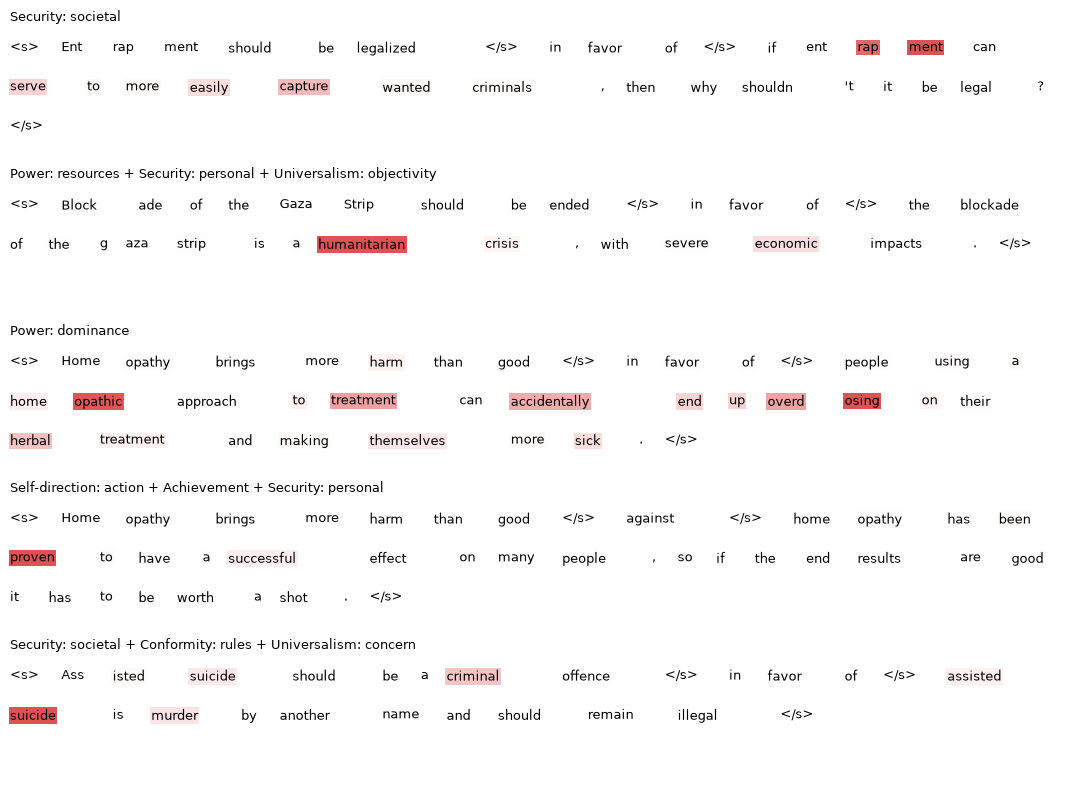

In [5]:
def afficher(ax, tokens, alpha, titre):
    m = max(alpha); x, y = 0.0, 0.9
    ax.set_axis_off(); ax.set_title(titre, fontsize=9, loc="left")
    for t, p in zip(tokens, alpha):
        t = t.replace("Ġ", "")
        if x + 0.012 * (len(t) + 1) > 1:
            x, y = 0.0, y - 0.32
        ax.text(x, y, t, fontsize=9, transform=ax.transAxes, va="top",
                bbox=dict(facecolor="tab:red", alpha=min(p / m, 1) * .8, edgecolor="none", pad=1))
        x += 0.012 * (len(t) + 1)

y = label_matrix(load_split("validation"))
choix = [i for i, a in enumerate(attn) if 22 <= len(a["tokens"]) <= 42][:400:80]
fig, axes = plt.subplots(5, 1, figsize=(11, 8))
for ax, i in zip(axes, choix):
    afficher(ax, attn[i]["tokens"], attn[i]["alpha"], " + ".join(v for v, b in zip(VALUES, y[i]) if b))
plt.tight_layout(); plt.savefig("../figures/D2_attention.png", dpi=120); plt.show()

**Lecture :**
- **Score :** D2 = 0,450 ± 0,004 (3 graines), proche de D1 (~0,445) et au-dessus de C1 (0,415). Le changement de représentation (GloVe → RoBERTa) apporte plus que la tête utilisée.
- **Attention (graine 42) :** 97,5 % sur la prémisse pour 61 % des tokens, 2,4 % sur la conclusion. C'est l'inverse de C2 (35 % sur la conclusion).
- **Mots :** cette fois, des mots proches des valeurs ressortent : *freedom* reçoit 12 fois sa part, *rights* et *health* ~5 fois ; aussi *financial*, *choice*, *free*, *money*, *dangerous*. Dans C2, *freedom* (1,1) et *rights* (0,7) n'avaient rien de particulier.
- **Négation :** *not* reçoit très peu (0,02), comme en C2. RoBERTa peut toutefois avoir déjà intégré cette information dans les états des mots voisins.
- Ces poids décrivent où le modèle regarde, pas pourquoi, et proviennent d'une seule graine.